# Bounding-Box Visualization

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

SEED = 42
NUM_SAMPLES = 16
DATA_PATH = "./data/train.pt"

In [2]:
data = torch.load(DATA_PATH, map_location="cpu")
images = data["images"].numpy().astype("float32") / 255.0
digit_labels = data["all_digit_labels"].numpy().astype("int64")
positions = data["all_positions"].numpy().astype("int64")

print(f"Images: {images.shape}")
print(f"Digit labels: {digit_labels.shape}")
print(f"Positions: {positions.shape}")

Images: (50000, 64, 64)
Digit labels: (50000, 8)
Positions: (50000, 8, 2)


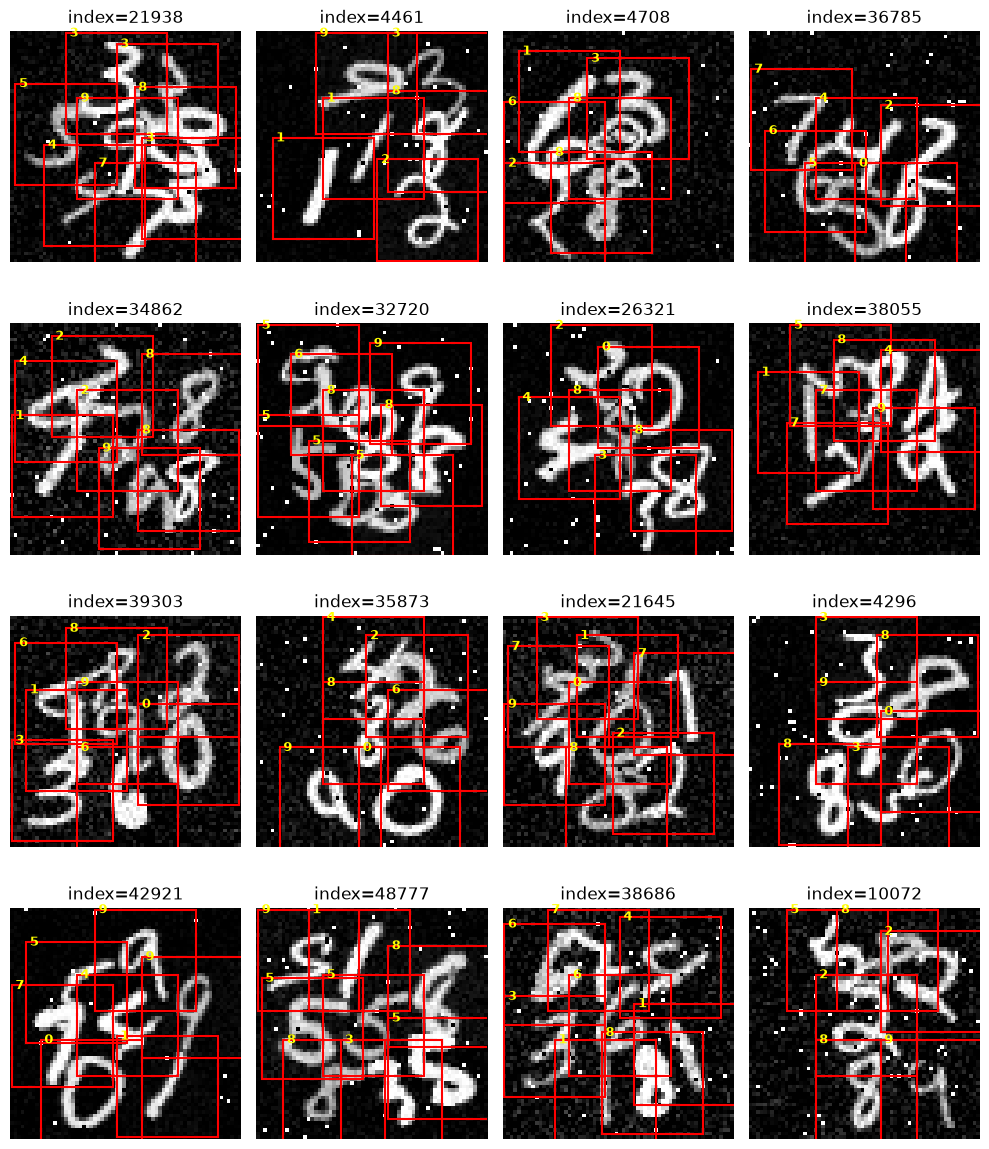

In [3]:
def draw_sample(ax, index):
    ax.imshow(images[index], cmap="gray", vmin=0, vmax=1)

    for digit, (x, y) in zip(digit_labels[index], positions[index]):
        if digit < 0 or x < 0 or y < 0:
            continue

        ax.add_patch(Rectangle((x, y), 28, 28, fill=False, edgecolor="red", linewidth=1.5))
        ax.text(x + 1, y + 1, str(digit), color="yellow", fontsize=9, weight="bold")

    ax.set_title(f"index={index}")
    ax.axis("off")

rng = np.random.default_rng(SEED)
indices = rng.choice(len(images), size=min(NUM_SAMPLES, len(images)), replace=False)
rows = int(np.ceil(len(indices) / 4))
fig, axes = plt.subplots(rows, 4, figsize=(10, 3 * rows))
axes = np.atleast_1d(axes).ravel()

for ax, index in zip(axes, indices):
    draw_sample(ax, index)

for ax in axes[len(indices):]:
    ax.axis("off")

plt.tight_layout()
plt.show()